# A rigorous FDTD mask model for lithography: lines against RCWA, and contact holes

Notebooks [36](36_litho_rigorous_mask.ipynb) and
[37](37_litho_mask_models.ipynb) compared the thin mask models
(Kirchhoff, film, boundary layer) with the RCWA of `litho.rcwa`, which
handles 1D layouts: lines and spaces. Contact holes, line ends and other
2D layouts need a rigorous model too, and that is what
`litho.FDTDMask` is: the same mask description and interface as
`RigorousMask`, solved with the 3D FDTD of `pyoptics.fdtd` (notebook
[64](64_fdtd_3d_nanojet.ipynb)) instead of with Fourier modes.

1. the **FDTD cell** of a mask: one period, Bloch boundaries, a plane-wave
   source in the blank and a diffraction monitor in the exit medium,
2. **near fields** at chrome and MoSi lines for the two polarizations,
3. the diffraction **orders through pitch** against RCWA, and their
   convergence with the cell size,
4. **oblique incidence** and **aerial images** with FDTD and RCWA masks,
5. **contact holes**: near field, orders and images against the film
   mask, where only the FDTD is rigorous.

The parameters are those of notebooks 32, 36 and 37: ArF immersion at
193 nm, NA 1.35, 4× reduction, a 68 nm MoSi attenuated PSM and a 70 nm
chrome binary mask. Lengths are in nm at **wafer scale** for layouts
and images, and at **mask scale** (4× larger) in the FDTD cell.
The runs use the numba kernels (`pip install pyoptics[fast]`).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import fdtd
from pyoptics.fdtd import plot as fplot
from pyoptics.litho import (FDTDMask, Illumination, LithoSimulation, MaskLayout, Projector,
                            RigorousMask, hopkins)

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
print("numba kernels available:", fdtd.numba_available)
t_start = time.perf_counter()

wl, n_w, NA, M = 193.0, 1.437, 1.35, 4.0
MOSI, CR, BLANK = 2.343 + 0.586j, 0.84 + 1.65j, 1.563  # as in notebooks 32, 36 and 37
stacks = {"MoSi": [(MOSI, 68.0)], "Cr": [(CR, 70.0)]}
names = {"MoSi": "MoSi 68 nm (6 % att. PSM)", "Cr": "Cr 70 nm (binary)"}
fdtd_mask = {k: FDTDMask(v, name=names[k]) for k, v in stacks.items()}
rcwa_mask = {k: RigorousMask(v, name=names[k]) for k, v in stacks.items()}
projector = Projector(NA, wl, n=n_w)
zero = np.zeros(1)
colors = {"MoSi": "C0", "Cr": "C3"}

for k, fm in fdtd_mask.items():
    med = fdtd.Medium.from_index(stacks[k][0][0].real, stacks[k][0][0].imag, wl)
    kind = f"Drude, plasma wavelength {2*np.pi/med.poles[0].omega_p:.0f} nm" if med.poles else \
        f"eps = {med.eps:.3f}, sigma = {med.sigma:.4f}"
    print(f"{fm.name}: eps = {complex(stacks[k][0][0])**2:.3f} -> FDTD medium {kind}, "
          f"eps(193 nm) = {med.complex_eps(wl):.3f}")

numba kernels available: True
MoSi 68 nm (6 % att. PSM): eps = 5.146+2.746j -> FDTD medium eps = 5.146, sigma = 0.0894, eps(193 nm) = 5.146+2.746j
Cr 70 nm (binary): eps = -2.017+2.772j -> FDTD medium Drude, plasma wavelength 82 nm, eps(193 nm) = -2.017+2.772j


## 1. The FDTD cell of a mask

`FDTDMask.simulation()` returns the run for one source point and
polarization, set up but not run, so it can be plotted (or given more
monitors):

* laterally **one period** of the layout at mask scale (pitch × 4), with
  **Bloch-periodic** boundaries whose phase is the transverse wave vector
  $k_t = k_0\,\mathrm{NA}\,s/M$ of the source point $s$ — oblique and
  conical incidence cost nothing extra,
* along the optical axis z: the **blank** (fused silica) below z = 0, the
  **absorber** on top of it, the **exit medium** (air) above, **PML** at
  both ends,
* a **plane current sheet** in the blank (amber) launches a pulsed plane
  wave polarized along x or y; a **diffraction monitor** in the exit
  medium (blue, dashed) expands the transmitted field into the orders
  (m, n) at the wavelength,
* the invariant direction of **lines and spaces is one cell wide**, so a
  1D layout costs as much as a 2D FDTD run; contact holes need the full 3D
  cell,
* each order is moved back to the bottom of the absorber with its
  (discrete) propagation constant and divided by the transmission of the
  **unpatterned stack** (a one-cell run at the same angle). The open frame
  then transmits 1, as for `RigorousMask`, and the source amplitude and
  the dispersion of the grid drop out.

Chrome has Re ε < 0 at 193 nm, which no positive permittivity can
represent. `fdtd.Medium.from_index(n, k, wavelength)` turns it into a
**Drude medium** that has exactly ε = (n + ik)² at the wavelength; MoSi
(Re ε > 1) becomes a dielectric with a conductivity. Metals are drawn in
a metallic colour.

lines, 130 nm pitch: 108 x 1 x 71 cells of 4.67 nm (wavelength/41)
contact holes, 140 nm pitch: 116 x 116 x 71 cells of 4.67 nm (wavelength/41)


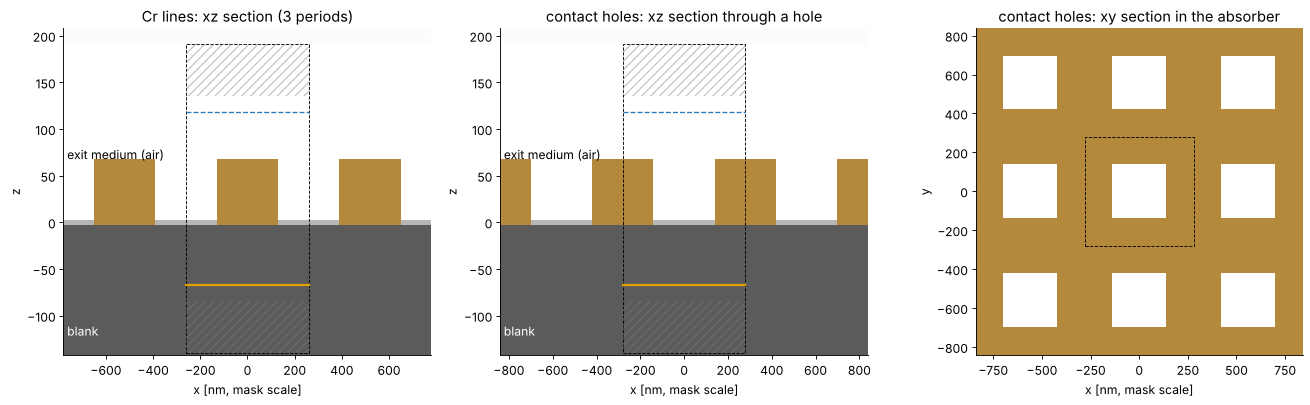

In [2]:
lines = MaskLayout.lines_spaces(130.0, 65.0)
holes = MaskLayout.contact_holes(140.0, 70.0)
cr = fdtd_mask["Cr"]
sim_l = cr.simulation(lines, NA, wl, M)
sim_h = cr.simulation(holes, NA, wl, M, max_order=2)
for name, s in (("lines, 130 nm pitch", sim_l), ("contact holes, 140 nm pitch", sim_h)):
    print(f"{name}: {' x '.join(map(str, s.grid.shape))} cells of {s.grid.spacing[2]:.2f} nm "
          f"(wavelength/{wl/s.grid.spacing[2]:.0f})")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1, 1, 1.1]})
fplot.plot_structure(sim_l, ax=axes[0], periods=3, plane=("y", 0.0))
axes[0].set_title("Cr lines: xz section (3 periods)")
fplot.plot_structure(sim_h, ax=axes[1], periods=3, plane=("y", 0.0))
axes[1].set_title("contact holes: xz section through a hole")
fplot.plot_structure(sim_h, ax=axes[2], periods=3, plane=("z", 35.0))
axes[2].set_title("contact holes: xy section in the absorber")
for ax in axes[:2]:
    ax.set_aspect("auto")
    ax.text(0.01, 0.06, "blank", transform=ax.transAxes, color="w")
    ax.text(0.01, 0.6, "exit medium (air)", transform=ax.transAxes)
for ax in axes:
    ax.set_xlabel(ax.get_xlabel() + " [nm, mask scale]")
plt.tight_layout()

## 2. Near fields at the absorber

Two runs per mask at normal incidence, with a `DFTField` monitor on the xz
section: E along x (**TM**, across the lines) and E along y (**TE**, along
the lines; the 2D FDTD of notebooks 57–63 calls these the Hz and Ez
modes). The cell is drawn first, the fields carry the outline of the
absorber; they are normalized to the field transmitted by the clear
stack.

8 s


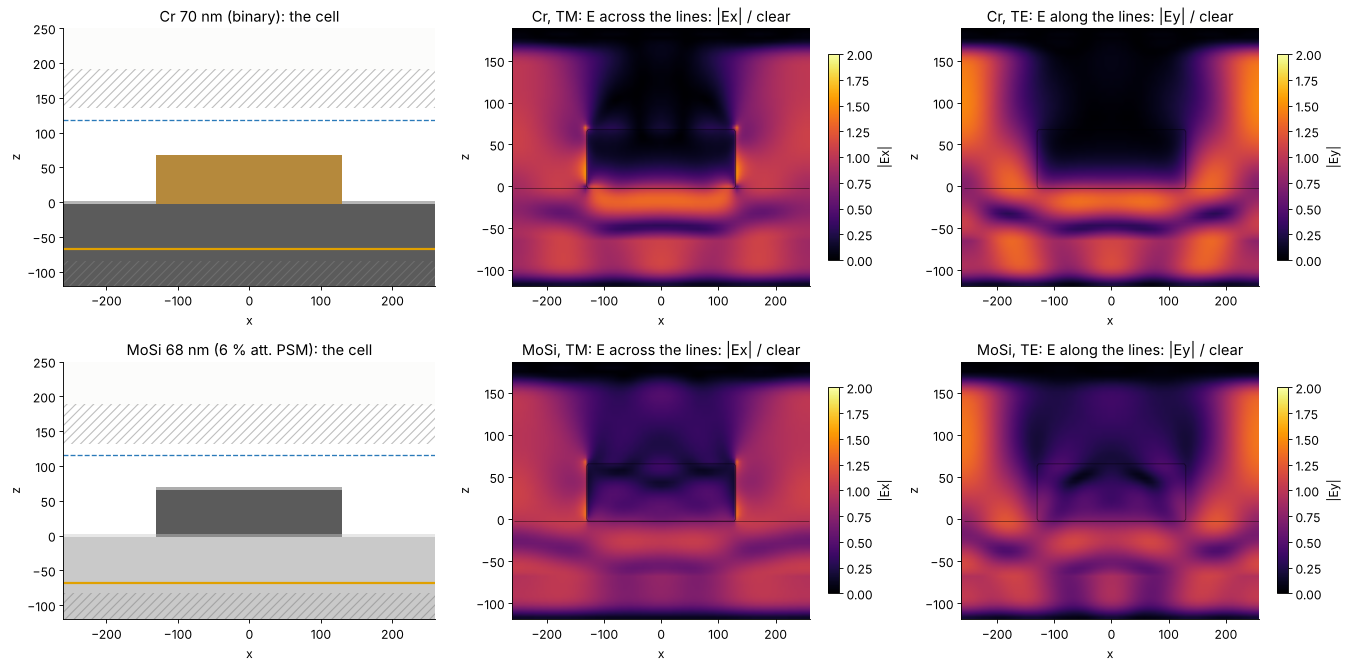

In [3]:
def near_field(fm, layout, component, plane_region, max_order=2, **kw):
    # DFT of the field on a section, normalized to the clear stack
    mon = fdtd.DFTField([wl], region=plane_region)
    sim = fm.simulation(layout, NA, wl, M, component=component, monitors=[mon], max_order=max_order, **kw)
    sim.run(time=fm.time*wl)
    ref = fdtd.DFTField([wl], components=[component], region=(None, None, fm.thickness + 40.0))
    clear = fm.simulation(layout, NA, wl, M, component=component, monitors=[ref], patterned=False, **kw)
    clear.run(time=fm.time*wl)
    t = np.abs(ref.data()[component]).mean()
    d = mon.data()
    return fdtd.DFTFieldData(d.wavelengths, {c: F/t for c, F in d.fields.items()}, d.coords, d.mode), sim


t0 = time.perf_counter()
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for row, k in zip(axes, ("Cr", "MoSi")):
    fm = fdtd_mask[k]
    for col, (comp, pol) in enumerate((("Ex", "TM: E across the lines"), ("Ey", "TE: E along the lines"))):
        d, sim = near_field(fm, lines, comp, (None, 0.0, (-120.0, 250.0)))
        if col == 0:
            fplot.plot_structure(sim, ax=row[0], periods=1)
            row[0].set_ylim(-120, 250); row[0].set_title(f"{fm.name}: the cell")
        fplot.plot_field(d, comp, ax=row[col + 1], sim=sim, part="abs", vmax=2.0,
                         title=f"{k}, {pol}: |{comp}| / clear")
for ax in axes.flat:
    ax.set_aspect("auto")
print(f"{time.perf_counter() - t0:.0f} s")
plt.tight_layout()

The TM field (E across the lines) is continuous in the normal component
of D, so it piles up at the vertical walls of the absorber and leaks
along them; the TE field (E along the lines) must be continuous in the
tangential component and is pushed out of the absorber. The chrome line
is nearly opaque in both cases, the MoSi line lets about 6 % of the
intensity through with a phase shift of about 180°, and the field behind
it already mixes with the field from the spaces within a fraction of a
wavelength: the "3D mask effects" that a thin mask model has to fake with
boundary layers (notebook 37).

## 3. Orders through pitch: FDTD against RCWA

For lines and spaces both models are rigorous, so they must agree. The
sketches show the cells (three periods each) at the smallest, a medium
and the largest pitch of the scan; the FDTD cell grows with the pitch,
RCWA needs more Fourier orders instead.

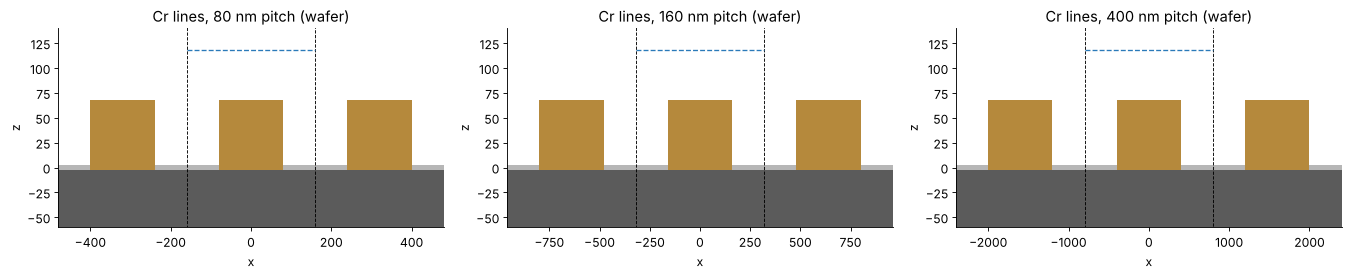

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, p in zip(axes, (80.0, 160.0, 400.0)):
    s = cr.simulation(MaskLayout.lines_spaces(p, p/2), NA, wl, M)
    fplot.plot_structure(s, ax=ax, periods=3, show_pml=False)
    ax.set_ylim(-60, 140); ax.set_aspect("auto")
    ax.set_title(f"Cr lines, {p:.0f} nm pitch (wafer)")
plt.tight_layout()

1242 s
MoSi: max. |FDTD − RCWA| over the orders −1, 0, 1: 80: 0.0049, 90: 0.0059, 100: 0.0052, 115: 0.0052, 130: 0.0050, 150: 0.0049, 180: 0.0040, 220: 0.0043, 260: 0.0041, 320: 0.0044, 400: 0.0041
Cr: max. |FDTD − RCWA| over the orders −1, 0, 1: 80: 0.0064, 90: 0.0055, 100: 0.0066, 115: 0.0059, 130: 0.0034, 150: 0.0050, 180: 0.0036, 220: 0.0029, 260: 0.0027, 320: 0.0018, 400: 0.0018


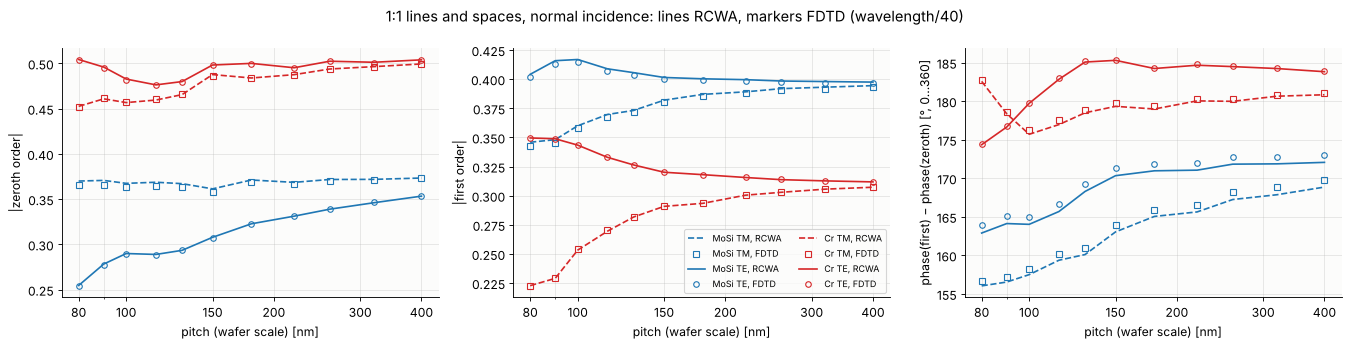

In [5]:
pitches = np.array([80, 90, 100, 115, 130, 150, 180, 220, 260, 320, 400.0])
m = np.arange(-1, 2)
orders = {}
t0 = time.perf_counter()
for k in stacks:
    for model, masks in (("FDTD", fdtd_mask), ("RCWA", rcwa_mask)):
        a = []
        for p in pitches:
            J = masks[k].order_jones(MaskLayout.lines_spaces(p, p/2), m, [0], zero, zero, NA, wl, M)[0][:, :, 0]
            a.append([J[0, 0], J[1, 1]])        # TM, TE
        orders[k, model] = np.array(a)          # (pitch, pol, order)
print(f"{time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for k in stacks:
    for pol, ls, mk in ((0, "--", "s"), (1, "-", "o")):
        pname = "TM" if pol == 0 else "TE"
        for model in ("RCWA", "FDTD"):
            a = orders[k, model][:, pol]
            kw = (dict(ls=ls, color=colors[k], label=f"{k} {pname}, RCWA") if model == "RCWA" else
                  dict(ls="none", marker=mk, ms=5, mfc="none", color=colors[k], label=f"{k} {pname}, FDTD"))
            axes[0].plot(pitches, np.abs(a[:, 1]), **kw)
            axes[1].plot(pitches, np.abs(a[:, 2]), **kw)
            axes[2].plot(pitches, np.degrees(np.angle(a[:, 2]/a[:, 1])) % 360, **kw)
axes[0].set_ylabel("|zeroth order|"); axes[1].set_ylabel("|first order|")
axes[2].set_ylabel("phase(first) − phase(zeroth) [°, 0…360]")
for ax in axes:
    ax.set_xscale("log"); ax.set_xticks([80, 100, 150, 200, 300, 400])
    ax.xaxis.set_major_formatter(plt.ScalarFormatter()); ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("pitch (wafer scale) [nm]"); ax.grid(alpha=0.3, which="both")
axes[1].legend(fontsize=8, ncol=2)
fig.suptitle("1:1 lines and spaces, normal incidence: lines RCWA, markers FDTD (wavelength/40)")
plt.tight_layout()

for k in stacks:
    d = np.abs(orders[k, "FDTD"] - orders[k, "RCWA"]).max(axis=(1, 2))
    print(f"{k}: max. |FDTD − RCWA| over the orders −1, 0, 1: " +
          ", ".join(f"{p:.0f}: {v:.4f}" for p, v in zip(pitches, d)))

The two solvers agree to better than 10⁻² of the clear-field amplitude
over the whole range, also at 80 nm pitch, where the first orders leave
the mask at about 50° (their direction sine at mask scale is
λ/(4·pitch)) and the TM orders of chrome depend most on the absorber
edges. That needs one detail: `FDTDMask` adjusts the cell size slightly
(never coarser, by up to 25 %) so that the edges of the features and the
absorber interfaces lie on grid nodes. A metal is a Drude medium, and the
subpixel averaging of a cell that is partly metal is poor; with edges
between nodes the TM orders of chrome lines were off by up to 4·10⁻².
Orders that are evanescent behind the mask cannot reach the lens; the
FDTD returns zero for them.

How fast does the FDTD converge? The error of the orders of the 130 nm
pitch against a 40-order RCWA reference, for cell sizes from λ/16 to λ/64
(the cell drawn for the coarsest and the finest grid first):

MoSi seconds per source point: [1.  1.4 1.8 2.7 3.7 5.8]


Cr seconds per source point: [0.9 1.3 2.1 2.9 4.2 5.4]
33 s


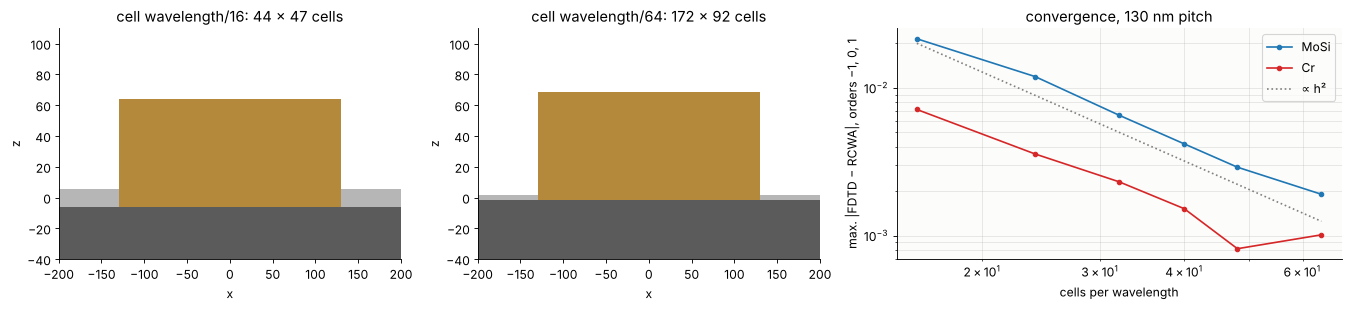

In [6]:
divs = np.array([16, 24, 32, 40, 48, 64])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.0), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, dv in zip(axes[:2], (divs[0], divs[-1])):
    s = FDTDMask(stacks["Cr"], spacing=wl/dv).simulation(lines, NA, wl, M)
    fplot.plot_structure(s, ax=ax, show_pml=False)
    ax.set_xlim(-200, 200); ax.set_ylim(-40, 110); ax.set_aspect("auto")
    ax.set_title(f"cell wavelength/{dv}: {s.grid.shape[0]} x {s.grid.shape[2]} cells")

t0 = time.perf_counter()
m2 = np.arange(-2, 3)
for k in stacks:
    ref = RigorousMask(stacks[k], n_orders=40).order_jones(lines, m2, [0], zero, zero, NA, wl, M)[0]
    err, cost = [], []
    for dv in divs:
        t1 = time.perf_counter()
        J = FDTDMask(stacks[k], spacing=wl/dv).order_jones(lines, m2, [0], zero, zero, NA, wl, M)[0]
        cost.append(time.perf_counter() - t1)
        err.append(np.abs(J - ref)[:, :, 0, 1:4].max())       # the orders that reach the pupil
    axes[2].loglog(divs, err, marker="o", ms=4, color=colors[k], label=k)
    print(k, "seconds per source point:", np.round(cost, 1))
axes[2].loglog(divs, 0.02*(divs/16.0)**-2, ":", color="gray", label="∝ h²")
axes[2].set_xlabel("cells per wavelength"); axes[2].set_ylabel("max. |FDTD − RCWA|, orders −1, 0, 1")
axes[2].set_title("convergence, 130 nm pitch"); axes[2].legend(); axes[2].grid(alpha=0.3, which="both")
print(f"{time.perf_counter() - t0:.0f} s")
plt.tight_layout()

With the edges on grid nodes the error falls as h², as it should for the
Yee scheme. The default of λ/40 (about 5 nm at mask scale) is a good
trade: a few 10⁻³ of the clear field, a couple of seconds per source
point for lines.

## 4. Oblique incidence and aerial images

Each source point of the illuminator hits the mask at its own angle
(at mask scale the angles are small: sin θ = NA·s/4 ≤ 0.34). In the FDTD
the angle is the phase of the Bloch boundaries; the sketch shows the
incident plane wave (real part of Ex in a clear run) for s_x = 0 and
s_x = 1 over three periods of the 130 nm MoSi lines.

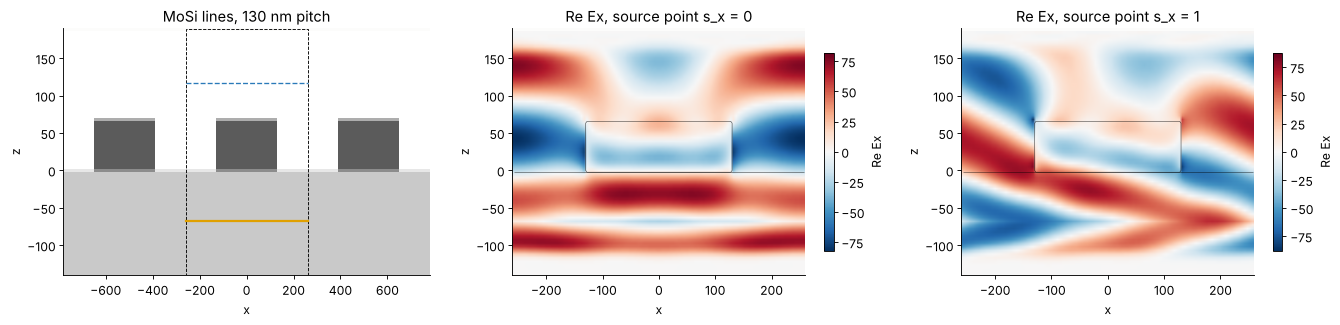

In [7]:
mosi = fdtd_mask["MoSi"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
fplot.plot_structure(mosi.simulation(lines, NA, wl, M), ax=axes[0], periods=3, show_pml=False)
axes[0].set_title("MoSi lines, 130 nm pitch"); axes[0].set_ylim(-140, 190)
for ax, s in zip(axes[1:], (0.0, 1.0)):
    mon = fdtd.DFTField([wl], components=["Ex"], region=(None, 0.0, None))
    sim = mosi.simulation(lines, NA, wl, M, s_x=s, monitors=[mon])
    sim.run(time=mosi.time*wl)
    fplot.plot_field(mon, "Ex", ax=ax, sim=sim, part="real", title=f"Re Ex, source point s_x = {s:.0f}")
    ax.set_ylim(-140, 190)
for ax in axes:
    ax.set_aspect("auto")
plt.tight_layout()

40 s, 54 patterned FDTD runs so far
$s_x$ (across the lines): max. |FDTD − RCWA| = 0.0050
$s_y$ (along the lines, conical): max. |FDTD − RCWA| = 0.0051


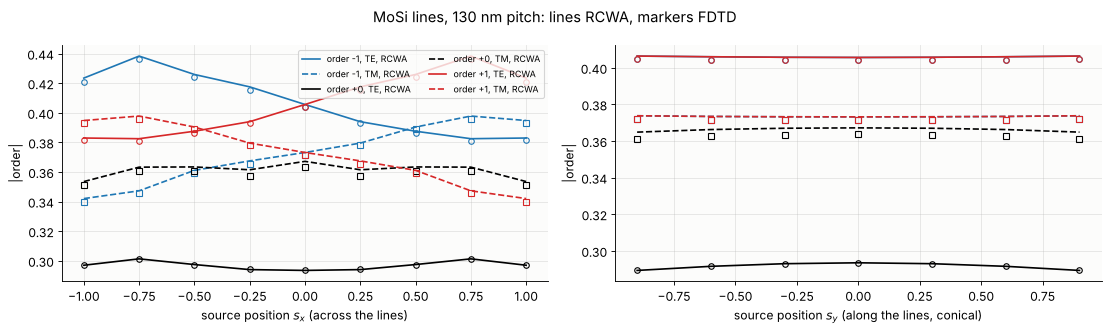

In [8]:
s = np.linspace(-1, 1, 9)
t0 = time.perf_counter()
J_f = mosi.order_jones(lines, m, [0], s, np.zeros_like(s), NA, wl, M)[:, :, :, 0]
J_r = rcwa_mask["MoSi"].order_jones(lines, m, [0], s, np.zeros_like(s), NA, wl, M)[:, :, :, 0]
s_c = np.linspace(-0.9, 0.9, 7)                     # conical incidence: s along the lines
J_fc = mosi.order_jones(lines, m, [0], np.zeros_like(s_c), s_c, NA, wl, M)[:, :, :, 0]
J_rc = rcwa_mask["MoSi"].order_jones(lines, m, [0], np.zeros_like(s_c), s_c, NA, wl, M)[:, :, :, 0]
print(f"{time.perf_counter() - t0:.0f} s, {mosi.runs} patterned FDTD runs so far")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (ss, Jf, Jr, lab) in zip(axes, ((s, J_f, J_r, "$s_x$ (across the lines)"),
                                       (s_c, J_fc, J_rc, "$s_y$ (along the lines, conical)"))):
    for i, (mm, c) in enumerate(((-1, "C0"), (0, "k"), (1, "C3"))):
        ax.plot(ss, np.abs(Jr[:, 1, 1, i]), "-", color=c, label=f"order {mm:+d}, TE, RCWA")
        ax.plot(ss, np.abs(Jr[:, 0, 0, i]), "--", color=c, label=f"order {mm:+d}, TM, RCWA")
        ax.plot(ss, np.abs(Jf[:, 1, 1, i]), "o", ms=5, mfc="none", color=c)
        ax.plot(ss, np.abs(Jf[:, 0, 0, i]), "s", ms=5, mfc="none", color=c)
    ax.set_xlabel(f"source position {lab}"); ax.set_ylabel("|order|"); ax.grid(alpha=0.3)
    print(f"{lab}: max. |FDTD − RCWA| = {np.abs(Jf - Jr).max():.4f}")
axes[0].legend(fontsize=8, ncol=2)
fig.suptitle("MoSi lines, 130 nm pitch: lines RCWA, markers FDTD")
plt.tight_layout()

The FDTD follows RCWA over the whole source, also for conical
incidence, where the cross-polarized parts of the Jones matrices appear.

An `FDTDMask` plugs into `LithoSimulation` like any mask stack. With
`incidence="per_point"` (the default) every source point gets its own
pair of runs (Abbe, as `RigorousMask`); with `incidence="normal"` the
orders at normal incidence are used for all of them (the Hopkins
approximation of the mask, two runs in total). TE-polarized annular
illumination, the 130 nm lines of both masks:

MoSi max. |FDTD − RCWA| of the image: 0.0022


Cr max. |FDTD − RCWA| of the image: 0.0003
81 s


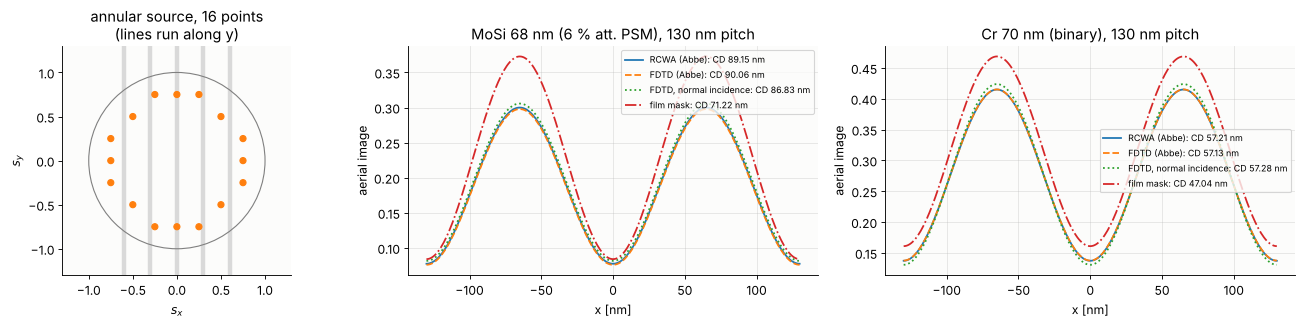

In [9]:
ill = Illumination.annular(0.9, 0.6, n_samples=9, polarization="TE")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [0.8, 1, 1]})
ax = axes[0]
ax.scatter(ill.s_x, ill.s_y, s=30*ill.weights/ill.weights.max(), color="C1")
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="gray"))
xs = np.linspace(-1.3, 1.3, 2)
for xl in (-0.6, -0.3, 0.0, 0.3, 0.6):
    ax.plot([xl, xl], [-1.3, 1.3], color="0.85", lw=4, zorder=0)
ax.set_aspect("equal"); ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3)
ax.set_title(f"annular source, {len(ill.s_x)} points\n(lines run along y)"); ax.set_xlabel("$s_x$"); ax.set_ylabel("$s_y$")

x = np.linspace(-130, 130, 261)
t0 = time.perf_counter()
for ax, k in zip(axes[1:], ("MoSi", "Cr")):
    models = {"RCWA (Abbe)": rcwa_mask[k], "FDTD (Abbe)": fdtd_mask[k],
              "FDTD, normal incidence": FDTDMask(stacks[k], incidence="normal"),
              "film mask": rcwa_mask[k].film_mask()}
    imgs = {name: LithoSimulation(lines, st, ill, projector).image(x) for name, st in models.items()}
    for (name, I), ls in zip(imgs.items(), ("-", "--", ":", "-.")):
        cd = LithoSimulation(lines, models[name], ill, projector).cd(0.25)
        ax.plot(x, I, ls, lw=1.6, label=f"{name}: CD {cd:.2f} nm")
    ax.set_xlabel("x [nm]"); ax.set_ylabel("aerial image"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    ax.set_title(f"{names[k]}, 130 nm pitch")
    print(k, "max. |FDTD − RCWA| of the image:", f"{np.abs(imgs['FDTD (Abbe)'] - imgs['RCWA (Abbe)']).max():.4f}")
print(f"{time.perf_counter() - t0:.0f} s")
plt.tight_layout()

The FDTD and RCWA images agree to a few 10⁻³ and their CDs at the
threshold 0.25 to about a nanometre, while the film mask is off by 10 to
20 nm (notebook 37). The Hopkins approximation of the mask
(`incidence="normal"`) costs about 2 nm of CD for MoSi and almost nothing
for chrome; it takes two runs instead of 32.

## 5. Contact holes

Square holes in chrome (dark field), 140 nm pitch and 70 nm size at
wafer scale. RCWA in pyoptics handles 1D layouts only, so the
comparison is with the film mask, whose orders are those of the ideal
layout times the film transmission and identical for both polarizations.
The FDTD cell is 3D (drawn in section 1), at λ/24 and 20 periods per run
to keep the time down (both change the orders by about 10⁻²
and 10⁻⁴).

First the field in the middle of the absorber for x polarization, on the
cell drawn on the left:

8 s


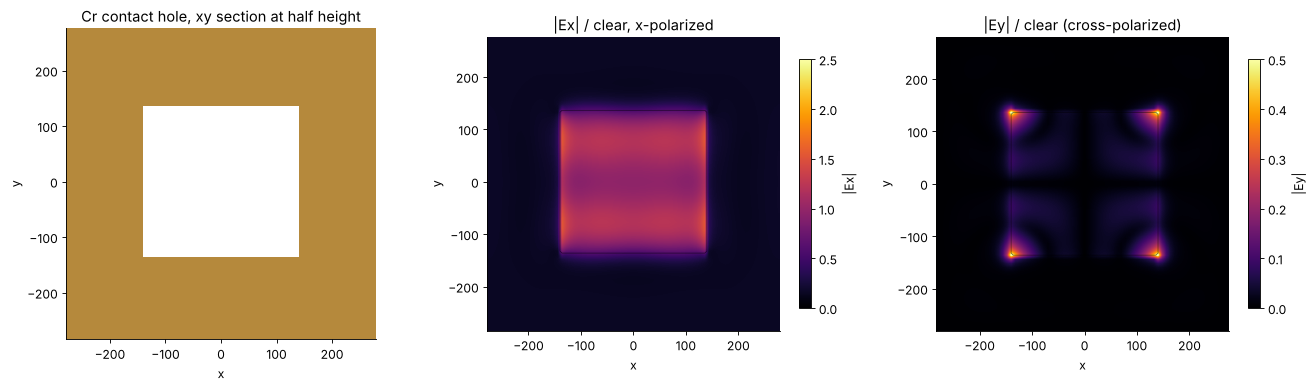

In [10]:
cr_h = FDTDMask(stacks["Cr"], spacing=wl/24, time=20, incidence="normal", name="Cr, FDTD")
t0 = time.perf_counter()
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
d_mid, sim_mid = near_field(cr_h, holes, "Ex", (None, None, 35.0))
fplot.plot_structure(sim_mid, ax=axes[0], plane=("z", 35.0), show_pml=False)
axes[0].set_title("Cr contact hole, xy section at half height")
fplot.plot_field(d_mid, "Ex", ax=axes[1], sim=sim_mid, part="abs", vmax=2.5,
                 title="|Ex| / clear, x-polarized")
fplot.plot_field(d_mid, "Ey", ax=axes[2], sim=sim_mid, part="abs", vmax=0.5,
                 title="|Ey| / clear (cross-polarized)")
print(f"{time.perf_counter() - t0:.0f} s")
plt.tight_layout()

The x-polarized field is TM at the two walls parallel to y (left and
right): it is strong there and reaches into the chrome, while at the
walls parallel to x it is TE and goes to zero. The hole therefore looks
**wider in x than in y** to an x-polarized wave, and the corners convert
some light into the cross polarization Ey. A thin mask has neither
effect.

The orders (m, n) of the hole array, for x polarization (FDTD) and for
the film mask, and the difference between the polarizations:

15 s


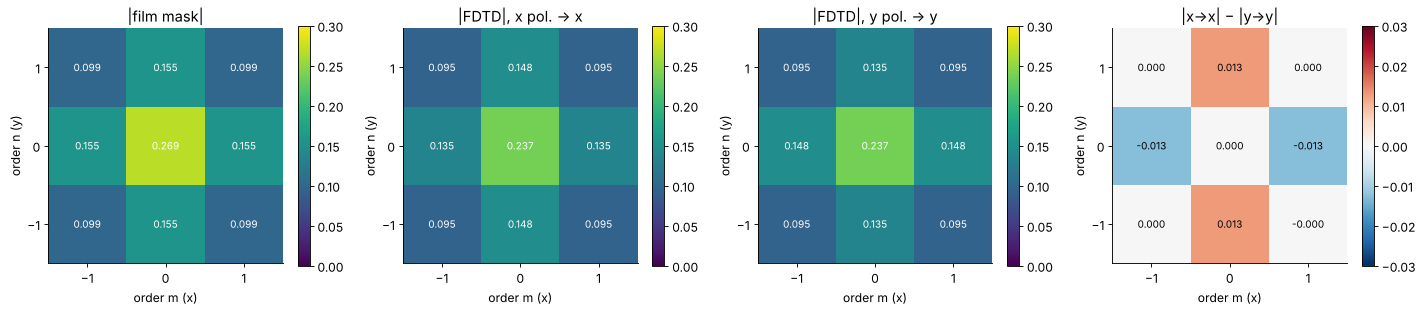

In [11]:
mn = np.arange(-1, 2)
t0 = time.perf_counter()
J_h = cr_h.order_jones(holes, mn, mn, zero, zero, NA, wl, M)[0]
J_film = rcwa_mask["Cr"].film_mask().jones(zero, zero, NA, wl, M)
c = holes.region_coefficients(mn, mn)
J_thin = c["field"]*np.asarray(J_film[1])[0][0, 0] + c["feature"]*np.asarray(J_film[0])[0][0, 0]
print(f"{time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
panels = ((np.abs(J_thin), "|film mask|"), (np.abs(J_h[0, 0]), "|FDTD|, x pol. → x"),
          (np.abs(J_h[1, 1]), "|FDTD|, y pol. → y"),
          (np.abs(J_h[0, 0]) - np.abs(J_h[1, 1]), "|x→x| − |y→y|"))
for ax, (A, t) in zip(axes, panels):
    diff = t.startswith("|x")
    im = ax.imshow(A, origin="lower", extent=(-1.5, 1.5, -1.5, 1.5),
                   cmap="RdBu_r" if diff else "viridis", vmin=-0.03 if diff else 0, vmax=0.03 if diff else 0.3)
    for (i, j), v in np.ndenumerate(A):
        ax.text(j - 1, i - 1, f"{v:.3f}", ha="center", va="center", color="k" if diff else "w", fontsize=9)
    ax.set_xticks(mn); ax.set_yticks(mn); ax.set_xlabel("order m (x)"); ax.set_ylabel("order n (y)")
    ax.set_title(t); plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()

The FDTD transmits less than the film mask in every order (the hole is
only 280 nm wide at mask scale, 1.5 wavelengths, and the walls of the
70 nm chrome shadow it), and the orders of the x-polarized wave are
weaker along x (m = ±1) than along y, as for a hole that is wider in x:
the transposed pattern for y polarization. Through pitch, with unpolarized and with x-polarized
annular illumination, the peak intensity and the printed size in x and
y (dose set to print a mean size of half the pitch):

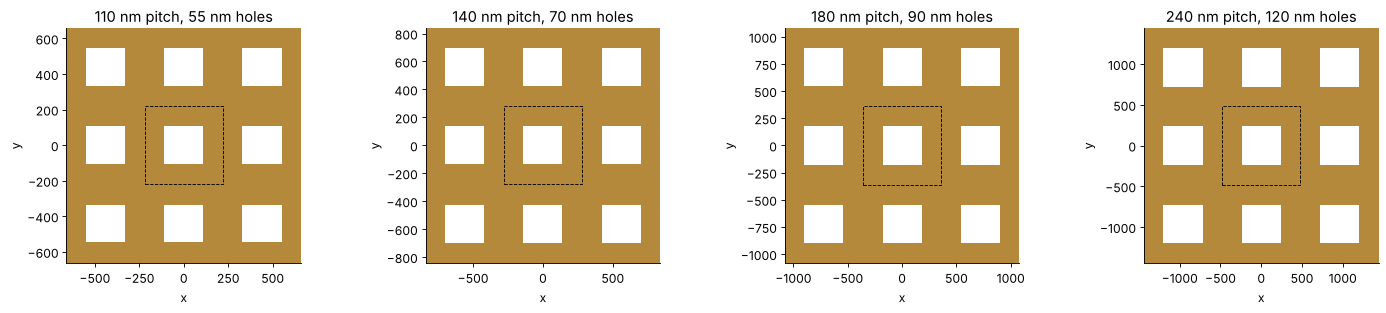

In [12]:
pitches_h = np.array([110.0, 140.0, 180.0, 240.0])
fig, axes = plt.subplots(1, 4, figsize=(18, 4.0))
for ax, p in zip(axes, pitches_h):
    s = cr_h.simulation(MaskLayout.contact_holes(p, p/2), NA, wl, M)
    fplot.plot_structure(s, ax=ax, plane=("z", 35.0), periods=3, show_pml=False)
    ax.set_title(f"{p:.0f} nm pitch, {p/2:.0f} nm holes")
plt.tight_layout()

82 s
('FDTD', 'unpolarized') CD_x − CD_y: [0. 0. 0. 0.] dose: [2.46 2.07 1.4  1.1 ]
('FDTD', 'x') CD_x − CD_y: [47.65 18.23 18.21 19.79] dose: [2.23 2.03 1.38 1.09]
('film', 'unpolarized') CD_x − CD_y: [ 0. -0.  0.  0.] dose: [1.83 1.67 1.23 0.99]
('film', 'x') CD_x − CD_y: [43.65 18.15 13.72 16.44] dose: [1.68 1.63 1.22 0.98]


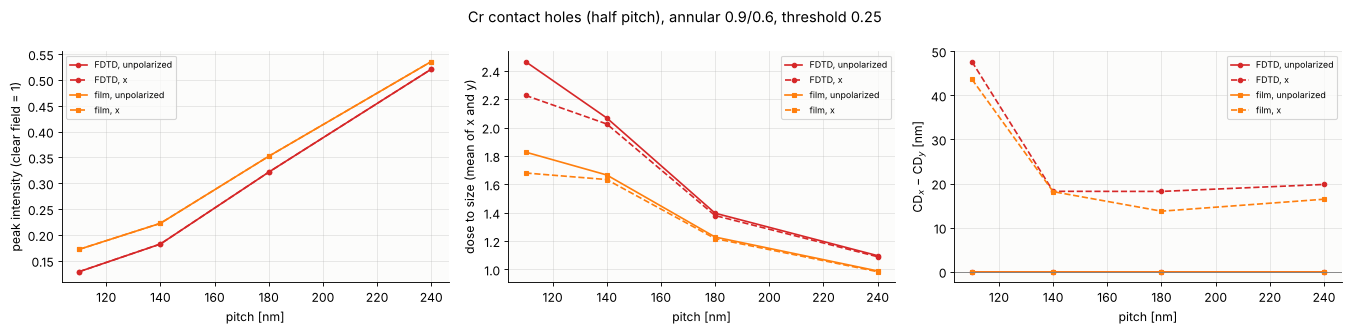

In [13]:
from scipy.optimize import brentq


def width(u, I, level):
    # width of the bright region around the centre of a cut (u centred on the hole)
    i0 = int(np.argmin(np.abs(u - u.mean())))
    if I[i0] < level:
        return 0.0
    above = I >= level
    lo, hi = i0, i0
    while lo > 0 and above[lo - 1]:
        lo -= 1
    while hi < len(u) - 1 and above[hi + 1]:
        hi += 1
    if lo == 0 or hi == len(u) - 1:
        return np.nan                      # holes merge
    edge = lambda a, b: u[a] + (level - I[a])*(u[b] - u[a])/(I[b] - I[a])
    return edge(hi, hi + 1) - edge(lo, lo - 1)


t0 = time.perf_counter()
rows = {}
for model, st in (("FDTD", cr_h), ("film", rcwa_mask["Cr"].film_mask())):
    for pol in ("unpolarized", "x"):
        out = []
        for p in pitches_h:
            sim = LithoSimulation(MaskLayout.contact_holes(p, p/2), st,
                                  Illumination.annular(0.9, 0.6, n_samples=9, polarization=pol), projector)
            (u_x, I_x), (u_y, I_y) = sim.cut(direction="x"), sim.cut(direction="y")
            mean_cd = lambda d: 0.5*(width(u_x, d*I_x, 0.25) + width(u_y, d*I_y, 0.25))
            d0 = brentq(lambda d: mean_cd(d) - p/2, 0.26/min(I_x.max(), I_y.max()), 0.25/max(I_x.min(), I_y.min()) - 1e-6)
            out.append((I_x.max(), width(u_x, d0*I_x, 0.25), width(u_y, d0*I_y, 0.25), d0))
        rows[model, pol] = np.array(out)
print(f"{time.perf_counter() - t0:.0f} s")
for k, r in rows.items():
    print(k, "CD_x − CD_y:", np.round(r[:, 1] - r[:, 2], 2), "dose:", np.round(r[:, 3], 2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for model, mk in (("FDTD", "o"), ("film", "s")):
    for pol, ls in (("unpolarized", "-"), ("x", "--")):
        r = rows[model, pol]
        kw = dict(marker=mk, ms=4, ls=ls, color="C3" if model == "FDTD" else "C1", label=f"{model}, {pol}")
        axes[0].plot(pitches_h, r[:, 0], **kw)
        axes[1].plot(pitches_h, r[:, 3], **kw)
        axes[2].plot(pitches_h, r[:, 1] - r[:, 2], **kw)
axes[0].set_ylabel("peak intensity (clear field = 1)")
axes[1].set_ylabel("dose to size (mean of x and y)")
axes[2].set_ylabel("CD$_x$ − CD$_y$ [nm]"); axes[2].axhline(0, color="gray", lw=0.8)
for ax in axes:
    ax.set_xlabel("pitch [nm]"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle("Cr contact holes (half pitch), annular 0.9/0.6, threshold 0.25")
plt.tight_layout()

* **Transmission:** the FDTD hole is darker than the film-mask hole,
  most of all at small pitch, so the dose to size is 10 % (240 nm pitch)
  to 35 % (110 nm) higher: the shadowing of thick absorbers that a thin
  mask misses.
* **Shape:** with unpolarized light both models print square holes. With
  x polarization the vector imaging alone (film mask) already makes the
  hole longer in x, by 14–18 nm (more at 110 nm pitch, where the holes
  almost merge along x); the mask adds up to 5 nm to that at the larger
  pitches. A model of the polarization dependence of 2D mask features
  needs a rigorous mask.

Finally the aerial images of the contacts at 140 nm pitch, x polarized
(the mask was drawn in section 1; here its holes are dashed):

total run time of the notebook: 1527 s


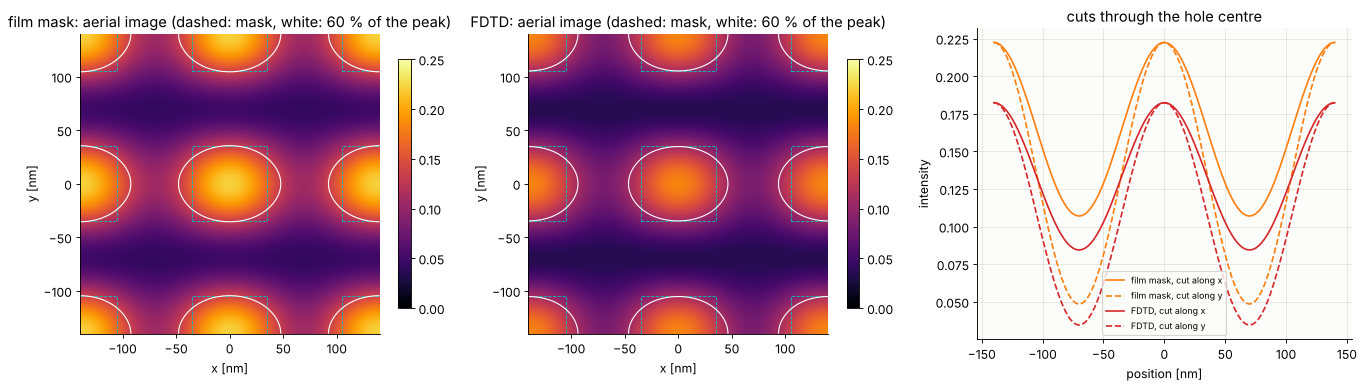

In [14]:
xs = np.linspace(-140, 140, 113)
il_x = Illumination.annular(0.9, 0.6, n_samples=9, polarization="x")
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
I = {}
for ax, (model, st) in zip(axes, (("film mask", rcwa_mask["Cr"].film_mask()), ("FDTD", cr_h))):
    I[model] = LithoSimulation(holes, st, il_x, projector).image(xs, xs)
    im = ax.imshow(I[model], origin="lower", extent=(xs[0], xs[-1], xs[0], xs[-1]), cmap="inferno",
                   vmin=0, vmax=0.25)
    ax.contour(xs, xs, I[model], levels=[0.6*I[model].max()], colors="w", linewidths=1)
    for xx in (-140, 0, 140):
        for yy in (-140, 0, 140):
            ax.add_patch(plt.Rectangle((xx - 35, yy - 35), 70, 70, fill=False, ec="c", lw=0.8, ls="--"))
    ax.set_title(f"{model}: aerial image (dashed: mask, white: 60 % of the peak)")
    ax.set_xlim(xs[0], xs[-1]); ax.set_ylim(xs[0], xs[-1])
    ax.set_xlabel("x [nm]"); ax.set_ylabel("y [nm]"); plt.colorbar(im, ax=ax, shrink=0.8)
i0 = len(xs)//2
for model, c in (("film mask", "C1"), ("FDTD", "C3")):
    axes[2].plot(xs, I[model][i0, :], color=c, label=f"{model}, cut along x")
    axes[2].plot(xs, I[model][:, i0], "--", color=c, label=f"{model}, cut along y")
axes[2].set_xlabel("position [nm]"); axes[2].set_ylabel("intensity"); axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3); axes[2].set_title("cuts through the hole centre")
plt.tight_layout()
print(f"total run time of the notebook: {time.perf_counter() - t_start:.0f} s")

## Summary

* `FDTDMask` is a rigorous mask stack for `LithoSimulation` and
  `hopkins.TCC` that handles any `MaskLayout`, 1D or 2D. It needs no
  Fourier orders; its accuracy is set by the cell size (λ/40 by default,
  about 10⁻² of the clear field for chrome and MoSi lines).
* For lines and spaces it agrees with RCWA in the orders, through pitch
  and over the source, and in the aerial images and CDs. RCWA is faster
  for lines; the FDTD is the reference for contact holes, line ends and
  other 2D features.
* Metals at a single wavelength enter as Drude media fitted exactly to
  (n + ik)² (`fdtd.Medium.from_index`).
* Cost: a few seconds per source point for lines, tens of seconds for
  contact holes at λ/24. `incidence="normal"` (two runs per layout)
  is enough at the small mask-side angles of 4× projection; the results
  are cached per layout and source.

Related: notebooks [36](36_litho_rigorous_mask.ipynb) (RCWA),
[37](37_litho_mask_models.ipynb) (thin mask models),
[62](62_fdtd_periodic_structures.ipynb) (periodic FDTD and diffraction
orders), [64](64_fdtd_3d_nanojet.ipynb) (3D FDTD).